# Modèle B — PCA pour la détection d'anomalies HDFS (Mouad)

## A. Objectif et introduction théorique

L'objectif est d'apprendre le comportement normal des blocs HDFS à partir de leurs 30 fréquences d'événements `E1` à `E30`, puis de signaler les blocs qui s'en écartent. Aucune étiquette n'est utilisée pour entraîner le modèle : l'apprentissage se fait exclusivement sur `train_normal`.

### Principe de l'ACP / PCA

Soit `X` la matrice des observations centrées, `X_c = X − μ`, où `μ` est la moyenne calculée sur les blocs normaux d'entraînement. La matrice de covariance est `C = (1/(n−1)) X_cᵀ X_c`. Les composantes principales sont les vecteurs propres `v_j` de `C` : `C v_j = λ_j v_j`, avec des valeurs propres `λ_1 ≥ λ_2 ≥ ... ≥ λ_d`. Elles définissent de nouveaux axes orthogonaux qui capturent la variance décroissante des données normales. La proportion de variance expliquée par l'axe `j` vaut `λ_j / Σ_i λ_i`.

En ne conservant que les `k` premières composantes (`W_k = [v_1 ... v_k]`), on projette un bloc `x` dans un espace de petite dimension : `z = W_kᵀ (x − μ)`. La reconstruction est `x̂ = μ + W_k z`. Plus `k` est grand, plus la reconstruction est fidèle ; trop petit, le modèle lisse les variations normales et génère des fausses alertes.

### Score d'anomalie

Le score retenu est l'erreur de reconstruction moyenne par caractéristique : `s(x) = (1/d) ‖x − x̂‖²`. Il est positif et croît quand le bloc est mal représenté par le sous-espace normal. Un bloc normal doit être reconstruit avec une faible erreur, car le modèle n'a vu que de tels blocs. Un bloc anormal peut contenir des combinaisons d'événements rares ou absentes de `train_normal` : sa projection perd alors une partie de l'information et son erreur de reconstruction augmente. Un score élevé indique donc un comportement éloigné de la normale.

### Seuil et protocole

Le seuil d'alerte est calculé avec la fonction commune `seuil()` : quantile 99,5 % des scores des blocs normaux de validation (`val_normal`). Les réglages (préprocessing, nombre de composantes) sont choisis au seul regard du F1 sur `val`. Le test n'est scoré qu'une fois, après figer le pipeline, et uniquement via `ecrire_predictions()` puis `evaluate.py`. La décomposition SVD utilisée est complète et déterministe ; la graine commune 42 est fixée par cohérence avec les règles du projet.

## B. Imports et chargement des données communes

In [1]:
import json
import os
import platform
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path("../..").resolve()))
from donnees import charger_compteurs, parties, seuil, ecrire_predictions, COLONNES_E, GRAINE

np.random.seed(GRAINE)
MACHINE = os.environ.get("PROCESSOR_IDENTIFIER") or platform.platform()
SORTIE = Path("../../results/pca_test.csv")
Path("figures").mkdir(exist_ok=True)
print("graine :", GRAINE)
print("machine :", MACHINE)

graine : 42
machine : Intel64 Family 6 Model 142 Stepping 10, GenuineIntel


In [2]:
df = charger_compteurs()
p = parties(df)

print("dimensions :", df.shape)
print("colonnes :", list(df.columns))
print("caractéristiques E :", len(COLONNES_E), COLONNES_E)
tableau_split = df.groupby("split")["label"].agg(
    blocs="size", anomalies="sum", normaux=lambda s: int((s == 0).sum()), taux_anomalie="mean"
)
display(tableau_split)
print("tailles des parties :", {nom: len(partie) for nom, partie in p.items()})

dimensions : (575061, 38)
colonnes : ['block_id', 'label', 'split', 'E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25', 'E26', 'E27', 'E28', 'E29', 'E30', 'n_warn', 'n_error', 'length', 'n_unique', 'duration_s']
caractéristiques E : 30 ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25', 'E26', 'E27', 'E28', 'E29', 'E30']


,blocs,anomalies,normaux,taux_anomalie
split,,,,
test,86260,1116,85144,0.012938
train,402542,13115,389427,0.032580
val,86259,2607,83652,0.030223


tailles des parties : {'train': 402542, 'train_normal': 389427, 'val': 86259, 'val_normal': 83652, 'test': 86260}


In [3]:
display(df.head())
description = df[COLONNES_E].describe().T[["mean", "std", "min", "50%", "max"]]
display(description.round(3))
somme_e = df[COLONNES_E].sum(axis=1)
print("somme E1..E30 par bloc :", somme_e.describe().round(2).to_dict())
constantes = [c for c in COLONNES_E if df[c].nunique() <= 1]
print("colonnes constantes :", constantes)
print("valeurs manquantes dans E :", int(df[COLONNES_E].isna().sum().sum()))

,block_id,label,split,E1,E2,E3,E4,E5,E6,E7,...,E26,E27,E28,E29,E30,n_warn,n_error,length,n_unique,duration_s
0,blk_-1608999687919862906,0,train,0,0,203,0,10,7,0,...,10,0,0,0,0,0,0,269,12,3802
1,blk_7503483334202473044,0,train,0,2,1,0,3,0,0,...,3,0,0,0,0,0,0,22,9,3802
2,blk_-3544583377289625738,1,train,0,0,203,0,3,0,0,...,3,0,0,0,0,1,0,223,9,3797
3,blk_-9073992586687739851,0,train,0,3,0,0,3,0,0,...,3,0,0,0,0,0,0,22,8,50448
4,blk_7854771516489510256,0,train,0,3,1,15,3,0,0,...,3,0,0,0,0,15,0,38,10,50583


,mean,std,min,50%,max
E1,0.000,0.006,0.0,0.0,2.0
E2,0.209,0.581,0.0,0.0,4.0
E3,0.746,2.517,0.0,0.0,203.0
E4,0.619,1.605,0.0,0.0,41.0
E5,2.997,0.221,1.0,3.0,13.0
E6,0.012,0.147,0.0,0.0,10.0
E7,0.006,0.081,0.0,0.0,5.0
E8,0.000,0.010,0.0,0.0,2.0
E9,2.968,0.310,0.0,3.0,3.0
E10,0.000,0.019,0.0,0.0,3.0


somme E1..E30 par bloc : {'count': 575061.0, 'mean': 19.43, 'std': 5.18, 'min': 2.0, '25%': 19.0, '50%': 19.0, '75%': 20.0, 'max': 298.0}
colonnes constantes : ['E22', 'E30']


valeurs manquantes dans E : 0


## C. Préparation des caractéristiques

Les comptages d'événements n'ont pas les mêmes échelles : `E5`, `E9`, `E11` et `E26` valent souvent 3, tandis que `E3` peut atteindre 203 et que certaines colonnes sont quasi constantes. On compare quatre stratégies justifiées :

| Stratégie | Définition | Intérêt | Risque |
|---|---|---|---|
| `brut` | comptages inchangés | respecte l'échelle naturelle ; les événements fréquents dominent | peut masquer les événements rares |
| `standard` | centrage-réduction appris sur `train_normal` | donne le même poids à chaque événement | amplifie le bruit des colonnes quasi constantes |
| `log_standard` | `log(1 + x)` puis centrage-réduction | compresse les fortes valeurs sans annuler les petites | change la métrique de reconstruction |
| `proportion_standard` | `x / somme(x)` puis centrage-réduction | compare la composition de chaque bloc indépendamment de sa longueur | perd l'information de longueur |

Tous les objets de préprocessing sont ajustés sur `train_normal` uniquement, puis appliqués tels quels à `val_normal`, `val` et `test`. Aucune étiquette n'intervient dans cette étape.

In [4]:
def proportions(x):
    return x / np.maximum(x.sum(axis=1, keepdims=True), 1.0)


def ajuster_preprocessing(nom, X):
    X = np.asarray(X, dtype=float)
    if nom == "brut":
        return {"nom": nom}, X.copy()
    if nom == "standard":
        scaler = StandardScaler().fit(X)
        return {"nom": nom, "scaler": scaler}, scaler.transform(X)
    if nom == "log_standard":
        X_log = np.log1p(X)
        scaler = StandardScaler().fit(X_log)
        return {"nom": nom, "scaler": scaler}, scaler.transform(X_log)
    if nom == "proportion_standard":
        X_prop = proportions(X)
        scaler = StandardScaler().fit(X_prop)
        return {"nom": nom, "scaler": scaler}, scaler.transform(X_prop)
    raise ValueError(f"préprocessing inconnu : {nom}")


def appliquer_preprocessing(etat, X):
    X = np.asarray(X, dtype=float)
    if etat["nom"] == "brut":
        return X.copy()
    if etat["nom"] == "standard":
        return etat["scaler"].transform(X)
    if etat["nom"] == "log_standard":
        return etat["scaler"].transform(np.log1p(X))
    if etat["nom"] == "proportion_standard":
        return etat["scaler"].transform(proportions(X))
    raise ValueError(f"préprocessing inconnu : {etat['nom']}")


def score_reconstruction(modele, X):
    Z = modele.transform(X)
    X_reconstruit = modele.inverse_transform(Z)
    return np.mean((X - X_reconstruit) ** 2, axis=1)


def mesures(y, pred):
    y = np.asarray(y, dtype=int)
    pred = np.asarray(pred, dtype=int)
    vp = int(((y == 1) & (pred == 1)).sum())
    fp = int(((y == 0) & (pred == 1)).sum())
    fn = int(((y == 1) & (pred == 0)).sum())
    vn = int(((y == 0) & (pred == 0)).sum())
    precision = vp / (vp + fp) if vp + fp else 0.0
    rappel = vp / (vp + fn) if vp + fn else 0.0
    f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else 0.0
    return {"precision": precision, "rappel": rappel, "f1": f1,
            "VP": vp, "FP": fp, "FN": fn, "VN": vn}

## D et E. Expériences PCA et sélection sur validation

Pour chaque configuration : ajuster le préprocessing sur `train_normal`, ajuster la PCA sur `train_normal`, calculer le score de `val_normal`, obtenir le seuil avec `seuil()`, calculer le score de toute la partie `val`, puis mesurer précision, rappel et F1. La SVD complète est utilisée pour éviter toute approximation aléatoire. Le nombre maximal d'essais est volontairement limité à 14 configurations couvrant les quatre préprocessings et des tailles de sous-espace raisonnables.

In [5]:
X_train_raw = p["train_normal"][COLONNES_E].to_numpy(dtype=float)
X_val_normal_raw = p["val_normal"][COLONNES_E].to_numpy(dtype=float)
X_val_raw = p["val"][COLONNES_E].to_numpy(dtype=float)
y_val = p["val"]["label"].to_numpy(dtype=int)

configurations = [
    {"preprocessing": "brut", "demande": 0.95, "nature": "variance"},
    {"preprocessing": "brut", "demande": 5, "nature": "entier"},
    {"preprocessing": "brut", "demande": 10, "nature": "entier"},
    {"preprocessing": "standard", "demande": 5, "nature": "entier"},
    {"preprocessing": "standard", "demande": 10, "nature": "entier"},
    {"preprocessing": "standard", "demande": 15, "nature": "entier"},
    {"preprocessing": "standard", "demande": 0.99, "nature": "variance"},
    {"preprocessing": "log_standard", "demande": 5, "nature": "entier"},
    {"preprocessing": "log_standard", "demande": 10, "nature": "entier"},
    {"preprocessing": "log_standard", "demande": 0.99, "nature": "variance"},
    {"preprocessing": "proportion_standard", "demande": 5, "nature": "entier"},
    {"preprocessing": "proportion_standard", "demande": 10, "nature": "entier"},
    {"preprocessing": "proportion_standard", "demande": 15, "nature": "entier"},
    {"preprocessing": "brut", "demande": 0.99, "nature": "variance"},
]

etats = {}
lignes = []
for i, configuration in enumerate(configurations, 1):
    debut = time.perf_counter()
    nom = configuration["preprocessing"]
    if nom not in etats:
        etats[nom] = ajuster_preprocessing(nom, X_train_raw)
    etat, X_train = etats[nom]
    X_val_normal = appliquer_preprocessing(etat, X_val_normal_raw)
    X_val = appliquer_preprocessing(etat, X_val_raw)
    modele = PCA(n_components=configuration["demande"], svd_solver="full").fit(X_train)
    score_val_normal = score_reconstruction(modele, X_val_normal)
    seuil_essai = seuil(score_val_normal)
    score_val = score_reconstruction(modele, X_val)
    mesures_essai = mesures(y_val, score_val > seuil_essai)
    variance_cumulee = float(np.cumsum(modele.explained_variance_ratio_)[-1])
    lignes.append({
        "essai": i,
        "preprocessing": nom,
        "demande": configuration["demande"],
        "nature": configuration["nature"],
        "n_composantes": int(modele.n_components_),
        "variance_cumulee": variance_cumulee,
        "seuil": float(seuil_essai),
        "precision_val": mesures_essai["precision"],
        "rappel_val": mesures_essai["rappel"],
        "f1_val": mesures_essai["f1"],
        "temps_s": time.perf_counter() - debut,
    })
    print(f"essai {i:2d} | {nom:20s} | k={lignes[-1]['n_composantes']:2d} "
          f"| F1 val {mesures_essai['f1']:.4f} | seuil {seuil_essai:.3e}")

resultats = pd.DataFrame(lignes)
resultats.to_csv("resultats_val_pca.csv", index=False)
display(resultats.sort_values("f1_val", ascending=False).reset_index(drop=True).round(6))

essai  1 | brut                 | k= 3 | F1 val 0.9549 | seuil 3.010e-02


essai  2 | brut                 | k= 5 | F1 val 0.9572 | seuil 2.227e-06


essai  3 | brut                 | k=10 | F1 val 0.9583 | seuil 5.647e-11


essai  4 | standard             | k= 5 | F1 val 0.9549 | seuil 3.270e-02


essai  5 | standard             | k=10 | F1 val 0.9394 | seuil 1.624e-08


essai  6 | standard             | k=15 | F1 val 0.9572 | seuil 1.631e-30


... (5 outputs left out)

essai 12 | proportion_standard  | k=10 | F1 val 0.9539 | seuil 1.735e-09


essai 13 | proportion_standard  | k=15 | F1 val 0.9558 | seuil 2.145e-30


essai 14 | brut                 | k= 4 | F1 val 0.9558 | seuil 4.045e-04


,essai,preprocessing,demande,nature,n_composantes,variance_cumulee,seuil,precision_val,rappel_val,f1_val,temps_s
0,3,brut,10.00,entier,10,0.999999,0.000000,0.982280,0.935558,0.958350,0.670824
1,2,brut,5.00,entier,5,0.999864,0.000002,0.917958,1.000000,0.957224,0.690653
2,6,standard,15.00,entier,15,1.000000,0.000000,0.917958,1.000000,0.957224,0.712565
3,10,log_standard,0.99,variance,8,0.997387,0.000041,0.917958,1.000000,0.957224,0.748526
4,9,log_standard,10.00,entier,10,0.999909,0.000000,0.916608,0.999233,0.956139,0.747577
5,13,proportion_standard,15.00,entier,15,1.000000,0.000000,0.915379,1.000000,0.955820,0.868805
6,14,brut,0.99,variance,4,0.992054,0.000404,0.915379,1.000000,0.955820,0.593222
7,1,brut,0.95,variance,3,0.961039,0.030101,0.913775,1.000000,0.954945,0.794285
8,4,standard,5.00,entier,5,0.819619,0.032698,0.913775,1.000000,0.954945,1.003482
9,12,proportion_standard,10.00,entier,10,0.999989,0.000000,0.912434,0.999233,0.953863,1.015823


In [6]:
classes = resultats.sort_values(
    ["f1_val", "n_composantes", "temps_s"], ascending=[False, True, True]
).reset_index(drop=True)
meilleur = classes.iloc[0]
print("Configuration retenue (F1 val maximal, départage par le modèle le plus simple) :")
print(meilleur.to_string())
print("\nMeilleures configurations :")
display(classes.head(6).round(6))

Configuration retenue (F1 val maximal, départage par le modèle le plus simple) :
essai                      3
preprocessing           brut
demande                 10.0
nature                entier
n_composantes             10
variance_cumulee    0.999999
seuil                    0.0
precision_val        0.98228
rappel_val          0.935558
f1_val               0.95835
temps_s             0.670824

Meilleures configurations :


,essai,preprocessing,demande,nature,n_composantes,variance_cumulee,seuil,precision_val,rappel_val,f1_val,temps_s
0,3,brut,10.00,entier,10,0.999999,0.000000,0.982280,0.935558,0.958350,0.670824
1,2,brut,5.00,entier,5,0.999864,0.000002,0.917958,1.000000,0.957224,0.690653
2,10,log_standard,0.99,variance,8,0.997387,0.000041,0.917958,1.000000,0.957224,0.748526
3,6,standard,15.00,entier,15,1.000000,0.000000,0.917958,1.000000,0.957224,0.712565
4,9,log_standard,10.00,entier,10,0.999909,0.000000,0.916608,0.999233,0.956139,0.747577
5,14,brut,0.99,variance,4,0.992054,0.000404,0.915379,1.000000,0.955820,0.593222


## F. Modèle final et prédictions sur le test

La configuration retenue est recréée de zéro sur `train_normal`. Le seuil est calculé sur `val_normal`, puis le F1 de validation est revérifié avec le pipeline final. Ce n'est qu'après ces étapes que les caractéristiques du test sont transformées et scorées, une seule fois.

In [7]:
nom_final = meilleur["preprocessing"]
demande_final = meilleur["demande"]
nature_final = meilleur["nature"]
debut_entrainement = time.perf_counter()
etat_final, X_train_final = ajuster_preprocessing(nom_final, X_train_raw)
parametre_pca = (float(demande_final) if nature_final == "variance" else int(demande_final))
modele_final = PCA(n_components=parametre_pca, svd_solver="full").fit(X_train_final)
temps_entrainement_s = time.perf_counter() - debut_entrainement

X_val_normal_final = appliquer_preprocessing(etat_final, X_val_normal_raw)
X_val_final = appliquer_preprocessing(etat_final, X_val_raw)
score_val_normal_final = score_reconstruction(modele_final, X_val_normal_final)
seuil_final = seuil(score_val_normal_final)
score_val_final = score_reconstruction(modele_final, X_val_final)
mesures_val_final = mesures(y_val, score_val_final > seuil_final)

print("préprocessing :", nom_final)
print("paramètre PCA :", parametre_pca, "(", nature_final, ")")
print("composantes retenues :", modele_final.n_components_)
print(f"temps d'entraînement : {temps_entrainement_s:.3f} s")
print(f"seuil (quantile 99,5 % val_normal) : {seuil_final:.10g}")
print(pd.Series(mesures_val_final).to_string())

préprocessing : brut
paramètre PCA : 10 ( entier )
composantes retenues : 10
temps d'entraînement : 0.549 s
seuil (quantile 99,5 % val_normal) : 5.646577813e-11
precision        0.982280
rappel           0.935558
f1               0.958350
VP            2439.000000
FP              44.000000
FN             168.000000
VN           83608.000000


In [8]:
X_test_raw = p["test"][COLONNES_E].to_numpy(dtype=float)
debut_pred = time.perf_counter()
X_test = appliquer_preprocessing(etat_final, X_test_raw)
score_test = score_reconstruction(modele_final, X_test)
predictions = ecrire_predictions(p["test"], score_test, seuil_final, str(SORTIE))
temps_pred_s = time.perf_counter() - debut_pred

fichier = pd.read_csv(SORTIE, dtype={"block_id": str})
ids_test = p["test"]["block_id"].astype(str)
assert list(fichier.columns) == ["block_id", "score", "pred"]
assert len(fichier) == len(p["test"])
assert not fichier["block_id"].duplicated().any()
assert set(fichier["block_id"]) == set(ids_test)
assert set(fichier["pred"].unique()) <= {0, 1}
assert np.isfinite(fichier["score"]).all()
assert np.allclose(fichier["score"].to_numpy(), score_test)
assert np.array_equal(fichier["pred"].to_numpy(), (fichier["score"] > seuil_final).astype(int).to_numpy())

print("fichier :", SORTIE.resolve())
print("lignes :", len(fichier), "; alertes :", int(fichier["pred"].sum()))
print(f"temps de prédiction sur le test : {temps_pred_s:.3f} s")
print("Tous les contrôles du fichier de prédictions sont passés.")
display(fichier.head())

fichier : C:\LOGsentinel\hdfs_v1\results\pca_test.csv
lignes : 86260 ; alertes : 1259
temps de prédiction sur le test : 0.414 s
Tous les contrôles du fichier de prédictions sont passés.


,block_id,score,pred
0,blk_3458545012440520721,2.983258e-13,0
1,blk_-1160437354072569825,2.983258e-13,0
2,blk_-8961379332018832424,2.983258e-13,0
3,blk_-7458466477853961957,2.983258e-13,0
4,blk_3070076663445833576,2.983258e-13,0


In [9]:
variance_ratio = modele_final.explained_variance_ratio_
detail_final = {
    "modele": "PCA",
    "membre": "Mouad",
    "preprocessing": nom_final,
    "parametre_pca": float(parametre_pca) if nature_final == "variance" else int(parametre_pca),
    "nature_composantes": nature_final,
    "n_composantes": int(modele_final.n_components_),
    "variance_cumulee": float(variance_ratio.sum()),
    "seuil": float(seuil_final),
    "validation": mesures_val_final,
    "train_time_s": round(temps_entrainement_s, 6),
    "train_time_min": round(temps_entrainement_s / 60, 6),
    "pred_time_s": round(temps_pred_s, 6),
    "machine": MACHINE,
    "fichier": SORTIE.name,
}
Path("mesures_pca.json").write_text(
    json.dumps(detail_final, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(detail_final, indent=2, ensure_ascii=False))

{
  "modele": "PCA",
  "membre": "Mouad",
  "preprocessing": "brut",
  "parametre_pca": 10,
  "nature_composantes": "entier",
  "n_composantes": 10,
  "variance_cumulee": 0.9999992936264809,
  "seuil": 5.646577812553519e-11,
  "validation": {
    "precision": 0.982279500604108,
    "rappel": 0.9355581127733027,
    "f1": 0.9583497053045187,
    "VP": 2439,
    "FP": 44,
    "FN": 168,
    "VN": 83608
  },
  "train_time_s": 0.549433,
  "train_time_min": 0.009157,
  "pred_time_s": 0.414055,
  "machine": "Intel64 Family 6 Model 142 Stepping 10, GenuineIntel",
  "fichier": "pca_test.csv"
}


## G. Analyse de la PCA retenue

Les graphiques ci-dessous montrent la variance expliquée, la distribution des erreurs de reconstruction sur la validation avec le seuil retenu, et la comparaison des F1 de validation. Ils servent à interpréter le choix final ; ils ne déclenchent aucun nouveau réglage.

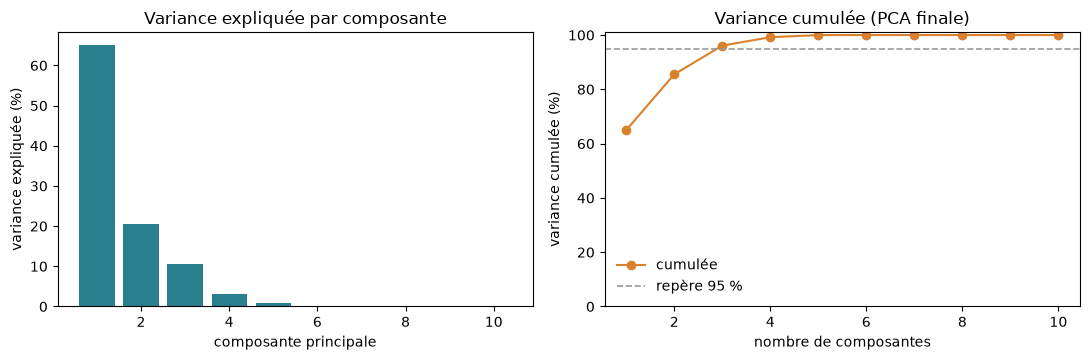

variance cumulée des 10 composantes : 0.999999
ratios : [6.4983e-01 2.0553e-01 1.0568e-01 3.1020e-02 7.8100e-03 8.0000e-05
 4.0000e-05 1.0000e-05 0.0000e+00 0.0000e+00]


In [10]:
k = modele_final.n_components_
cumulee = np.cumsum(variance_ratio) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].bar(range(1, k + 1), variance_ratio * 100, color="#2A7F8E")
axes[0].set_title("Variance expliquée par composante")
axes[0].set_xlabel("composante principale")
axes[0].set_ylabel("variance expliquée (%)")
axes[1].plot(range(1, k + 1), cumulee, marker="o", color="#D9822B", label="cumulée")
axes[1].axhline(95, color="#999999", ls="--", lw=1.2, label="repère 95 %")
axes[1].set_title("Variance cumulée (PCA finale)")
axes[1].set_xlabel("nombre de composantes")
axes[1].set_ylabel("variance cumulée (%)")
axes[1].set_ylim(0, 101)
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig("figures/pca_variance.png", dpi=150)
plt.show()
print(f"variance cumulée des {k} composantes : {variance_ratio.sum():.6f}")
print("ratios :", np.round(variance_ratio, 5))

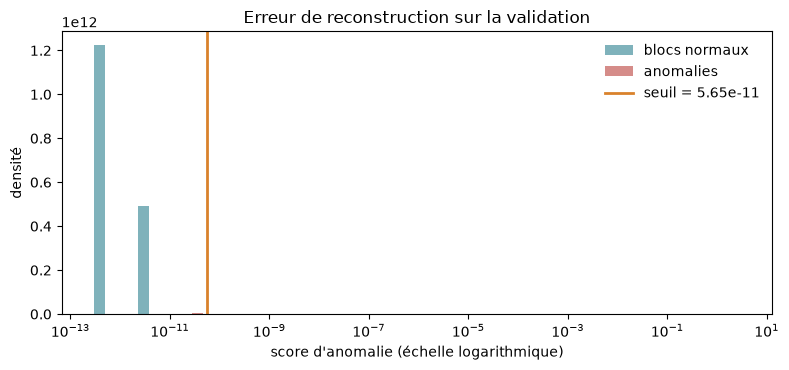

score médian normal : 2.657537209629739e-12
score médian anomalie : 1.762571092866058e-09


In [11]:
positifs = score_val_final[score_val_final > 0]
base = float(positifs.min()) if len(positifs) else 1e-15
bornes = np.logspace(np.log10(base), np.log10(float(score_val_final.max()) + base), 60)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(score_val_final[y_val == 0], bins=bornes, density=True, alpha=0.6,
        color="#2A7F8E", label="blocs normaux")
ax.hist(score_val_final[y_val == 1], bins=bornes, density=True, alpha=0.6,
        color="#B9403A", label="anomalies")
ax.axvline(seuil_final, color="#D9822B", lw=2, label=f"seuil = {seuil_final:.2e}")
ax.set_xscale("log")
ax.set_title("Erreur de reconstruction sur la validation")
ax.set_xlabel("score d'anomalie (échelle logarithmique)")
ax.set_ylabel("densité")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("figures/pca_scores_val.png", dpi=150)
plt.show()
print("score médian normal :", float(np.median(score_val_final[y_val == 0])))
print("score médian anomalie :", float(np.median(score_val_final[y_val == 1])))

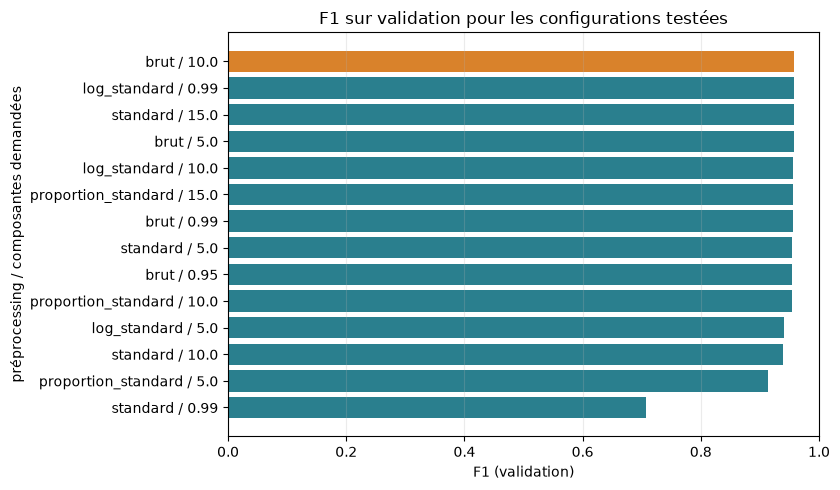

In [12]:
trie = resultats.sort_values("f1_val")
etiquettes = trie["preprocessing"].astype(str) + " / " + trie["demande"].astype(str)
couleurs = ["#D9822B" if int(v) == int(meilleur["essai"]) else "#2A7F8E" for v in trie["essai"]]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(etiquettes, trie["f1_val"], color=couleurs)
ax.set_title("F1 sur validation pour les configurations testées")
ax.set_xlabel("F1 (validation)")
ax.set_ylabel("préprocessing / composantes demandées")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig("figures/pca_comparaison_f1.png", dpi=150)
plt.show()

## H. Résumé report-ready

La PCA apprend le sous-espace des blocs normaux à partir de `train_normal` uniquement. Le score est l'erreur de reconstruction moyenne dans l'espace des caractéristiques prétraitées ; le seuil est le quantile 99,5 % des scores de `val_normal`. Quatorze configurations raisonnables, couvrant quatre préprocessings et plusieurs tailles de sous-espace, ont été comparées sur le F1 de validation. La meilleure configuration est recréée sur toutes les données normales d'entraînement, puis le test est scoré une seule fois.

Le détail exact (configuration retenue, variance expliquée, seuil, mesures de validation, temps réels d'entraînement et de prédiction) est dans `mesures_pca.json` ; le tableau complet des essais est dans `resultats_val_pca.csv`. Les chiffres officiels sur test sont ceux ajoutés par `evaluate.py` dans `results/summary.csv`. Limitations attendues : la PCA est un modèle linéaire sur des comptages, elle ignore l'ordre des événements et peut manquer les anomalies dont la distribution d'événements reste proche de la normale.